# Assignment 7: Image Sharpening

Sharpen an input image using:

1. Laplacian filter
2. Gradient operators: Sobel and the Canny edge detector
3. Unsharp masking, with the blurred image from a $5 \times 5$ Gaussian filter with $\sigma = 3$

**Requirements:** `pip install numpy matplotlib opencv-python scikit-image`

## Setup

To use your own image, set `INPUT_PATH`, for example `INPUT_PATH = "input.jpg"`. If it is left as `None`, a sample image from scikit-image is used. The strength settings can also be changed here.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from skimage import data

INPUT_PATH = None

LAPLACIAN_K = 1.0    # strength of Laplacian sharpening
SOBEL_K = 0.5        # strength of Sobel sharpening
CANNY_K = 0.15       # strength of Canny sharpening
UNSHARP_K = 3.0      # k = 1 is unsharp masking, k > 1 is highboost filtering

if INPUT_PATH is None:
    image = data.camera()
else:
    image = cv2.imread(INPUT_PATH, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {INPUT_PATH}")

print("Image shape:", image.shape)

Image shape: (512, 512)


In [2]:
def convolve(img, kernel):
    """Convolve using replicate padding. The result is a float array."""
    a = kernel.shape[0] // 2
    padded = np.pad(img.astype(float), a, mode="edge")
    windows = sliding_window_view(padded, kernel.shape)
    return np.einsum("ijkl,kl->ij", windows, kernel[::-1, ::-1])


def to_uint8(img):
    """Clip values to the 8-bit range."""
    return np.clip(np.round(img), 0, 255).astype(np.uint8)


def scale_for_display(img):
    """Stretch any range of values to 0-255 so that it can be displayed."""
    img = img.astype(float)
    span = img.max() - img.min()
    return np.zeros(img.shape, np.uint8) if span == 0 else to_uint8(255 * (img - img.min()) / span)


def show(images, titles, cols=3, size=5):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, img, title in zip(axes.ravel(), images, titles):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

## 1. Laplacian filter

The Laplacian is a second derivative, so it responds strongly to rapid changes in intensity:

$$\nabla^2 f = f(x+1,y) + f(x-1,y) + f(x,y+1) + f(x,y-1) - 4f(x,y)$$

Because the centre coefficient of this kernel is negative, the Laplacian is subtracted from the image to sharpen it:

$$g(x,y) = f(x,y) - k\,\nabla^2 f(x,y)$$

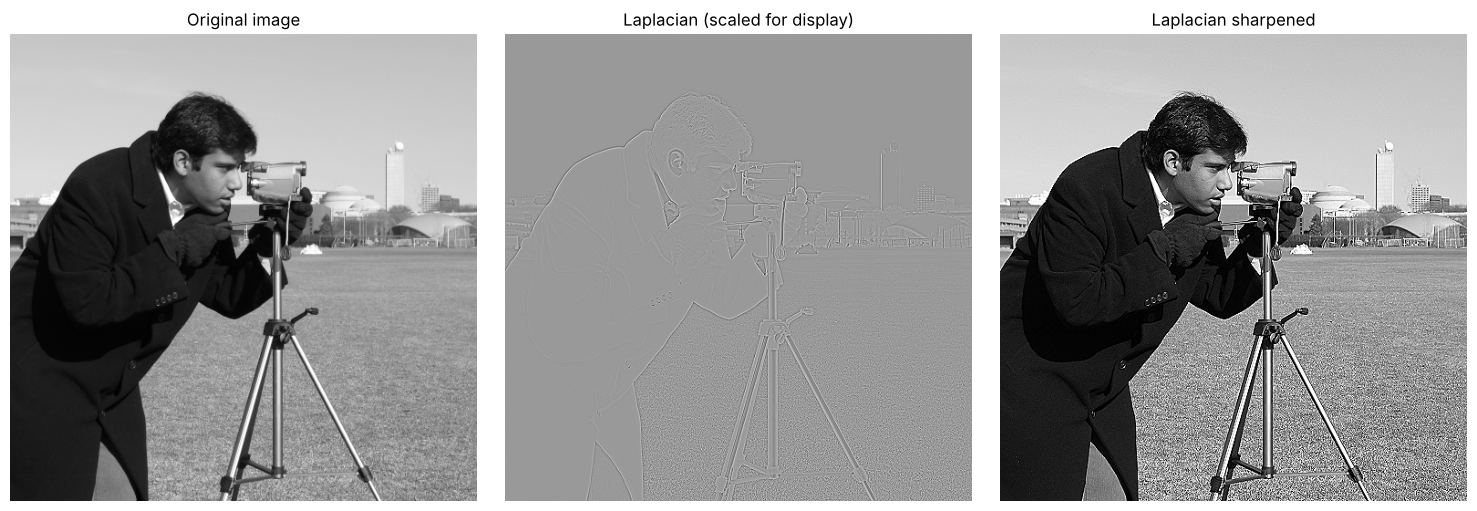

In [3]:
laplacian_kernel = np.array([[0, 1, 0],
                             [1, -4, 1],
                             [0, 1, 0]], dtype=float)

laplacian = convolve(image, laplacian_kernel)
laplacian_sharpened = to_uint8(image - LAPLACIAN_K * laplacian)

show([image, scale_for_display(laplacian), laplacian_sharpened],
     ["Original image", "Laplacian (scaled for display)", "Laplacian sharpened"])

## 2(a). Sobel gradient operator

The Sobel kernels estimate the first derivative in each direction:

$$G_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix} * f, \qquad G_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix} * f, \qquad M = \sqrt{G_x^2 + G_y^2}$$

The magnitude is scaled to the range 0 to 255 and added to the image:

$$g(x,y) = f(x,y) + k\,M(x,y)$$

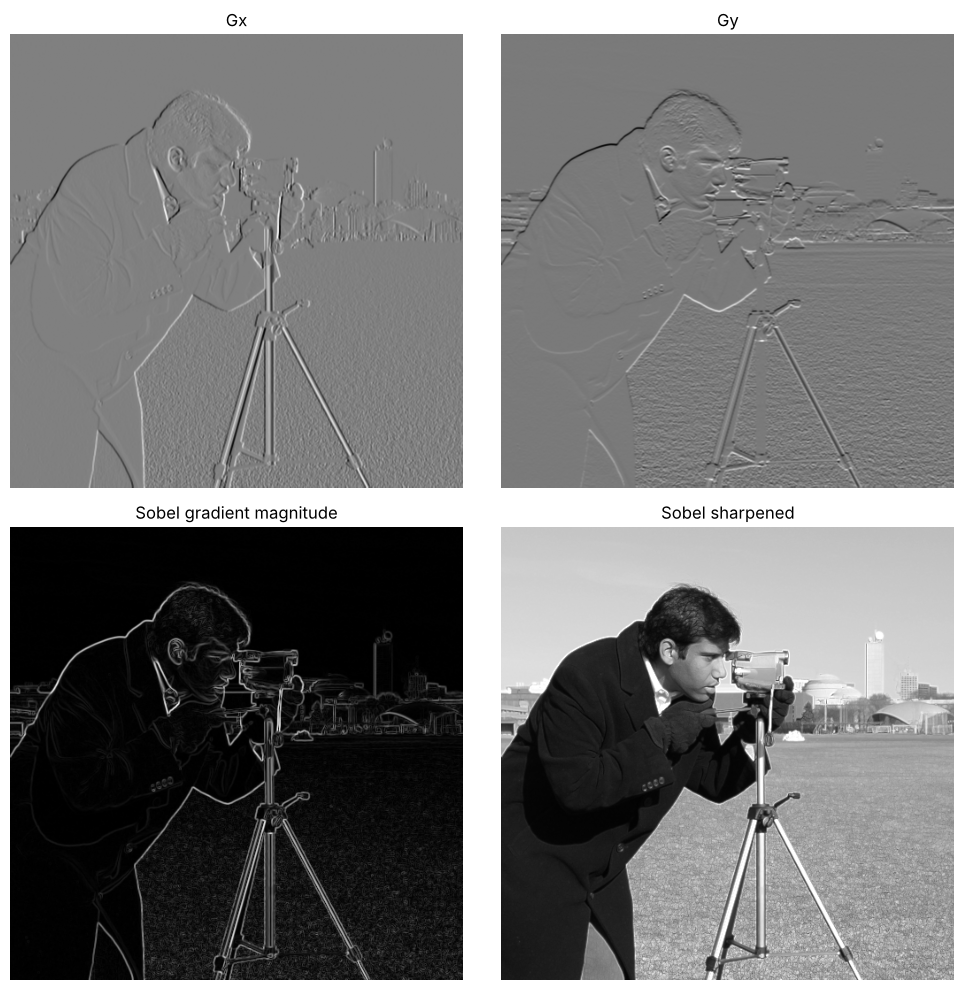

In [4]:
# The kernels are flipped because convolve() flips them again, so the signs match the matrices above.
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=float)


def sobel_gradients(img):
    gx = convolve(img, sobel_x[::-1, ::-1])
    gy = convolve(img, sobel_y[::-1, ::-1])
    return gx, gy


gx, gy = sobel_gradients(image)
sobel_magnitude = np.hypot(gx, gy)
sobel_scaled = 255 * sobel_magnitude / sobel_magnitude.max()
sobel_sharpened = to_uint8(image + SOBEL_K * sobel_scaled)

show([scale_for_display(gx), scale_for_display(gy), to_uint8(sobel_scaled), sobel_sharpened],
     ["Gx", "Gy", "Sobel gradient magnitude", "Sobel sharpened"], cols=2)

## 2(b). Canny edge detector

**Steps**

1. Smooth the image with a Gaussian filter.
2. Compute the gradient magnitude and direction with the Sobel operators.
3. Apply non-maximum suppression to thin the edges.
4. Apply a double threshold to label pixels as strong edges, weak edges or non-edges.
5. Use hysteresis to keep weak edges only if they connect to strong edges.

The edge map $E$ contains 0 and 255. It is added to the image in the same way as the gradient:

$$g(x,y) = f(x,y) + k\,E(x,y)$$

Since Canny gives thin binary edges, this mainly brightens the edge lines rather than increasing the contrast on both sides of an edge.

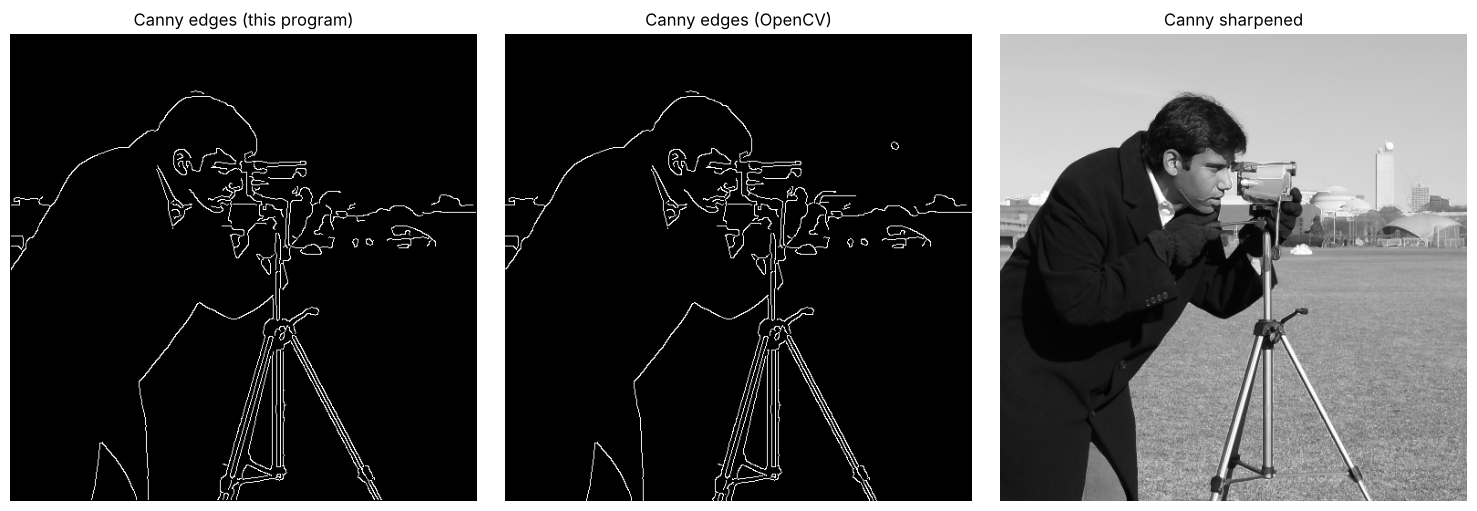

In [5]:
def gaussian_kernel(size, sigma):
    a = size // 2
    x, y = np.mgrid[-a:a + 1, -a:a + 1]
    h = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return h / h.sum()


def non_max_suppression(magnitude, gx, gy):
    """Keep only pixels that are local maxima along the gradient direction."""
    angle = np.rad2deg(np.arctan2(gy, gx)) % 180
    sector = (((angle + 22.5) % 180) // 45).astype(int)   # 0, 45, 90 or 135 degrees
    steps = [(0, 1), (1, 1), (1, 0), (1, -1)]             # (row, column) step for each sector

    keep = np.zeros(magnitude.shape, dtype=bool)
    m = magnitude
    for i, (dr, dc) in enumerate(steps):
        ahead = np.roll(m, (-dr, -dc), axis=(0, 1))
        behind = np.roll(m, (dr, dc), axis=(0, 1))
        keep |= (sector == i) & (m >= ahead) & (m >= behind)

    result = np.where(keep, m, 0.0)
    result[[0, -1], :] = 0
    result[:, [0, -1]] = 0
    return result


def hysteresis(strong, weak):
    """Keep weak edges that are connected to a strong edge."""
    edges = strong.copy()
    stack = list(zip(*np.nonzero(strong)))
    rows, cols = strong.shape
    while stack:
        r, c = stack.pop()
        for nr in range(max(r - 1, 0), min(r + 2, rows)):
            for nc in range(max(c - 1, 0), min(c + 2, cols)):
                if weak[nr, nc] and not edges[nr, nc]:
                    edges[nr, nc] = True
                    stack.append((nr, nc))
    return edges


def canny(img, size=5, sigma=1.4, low=50, high=150):
    smoothed = convolve(img, gaussian_kernel(size, sigma))
    gx, gy = sobel_gradients(smoothed)
    thin = non_max_suppression(np.hypot(gx, gy), gx, gy)
    edges = hysteresis(thin >= high, thin >= low)
    return edges.astype(np.uint8) * 255


canny_edges = canny(image)
canny_sharpened = to_uint8(image + CANNY_K * canny_edges.astype(float))

# OpenCV's Canny, for comparison
smoothed_for_cv = cv2.GaussianBlur(image, (5, 5), 1.4)
canny_cv = cv2.Canny(smoothed_for_cv, 50, 150, L2gradient=True)

show([canny_edges, canny_cv, canny_sharpened],
     ["Canny edges (this program)", "Canny edges (OpenCV)", "Canny sharpened"])

## 3. Unsharp masking

1. Blur the image with a $5 \times 5$ Gaussian filter with $\sigma = 3$.
2. Subtract the blurred image from the original to get the mask.
3. Add a multiple of the mask to the original.

$$\text{mask}(x,y) = f(x,y) - \bar{f}(x,y), \qquad g(x,y) = f(x,y) + k\,\text{mask}(x,y)$$

$k = 1$ is standard unsharp masking and $k > 1$ is highboost filtering. This notebook shows both.

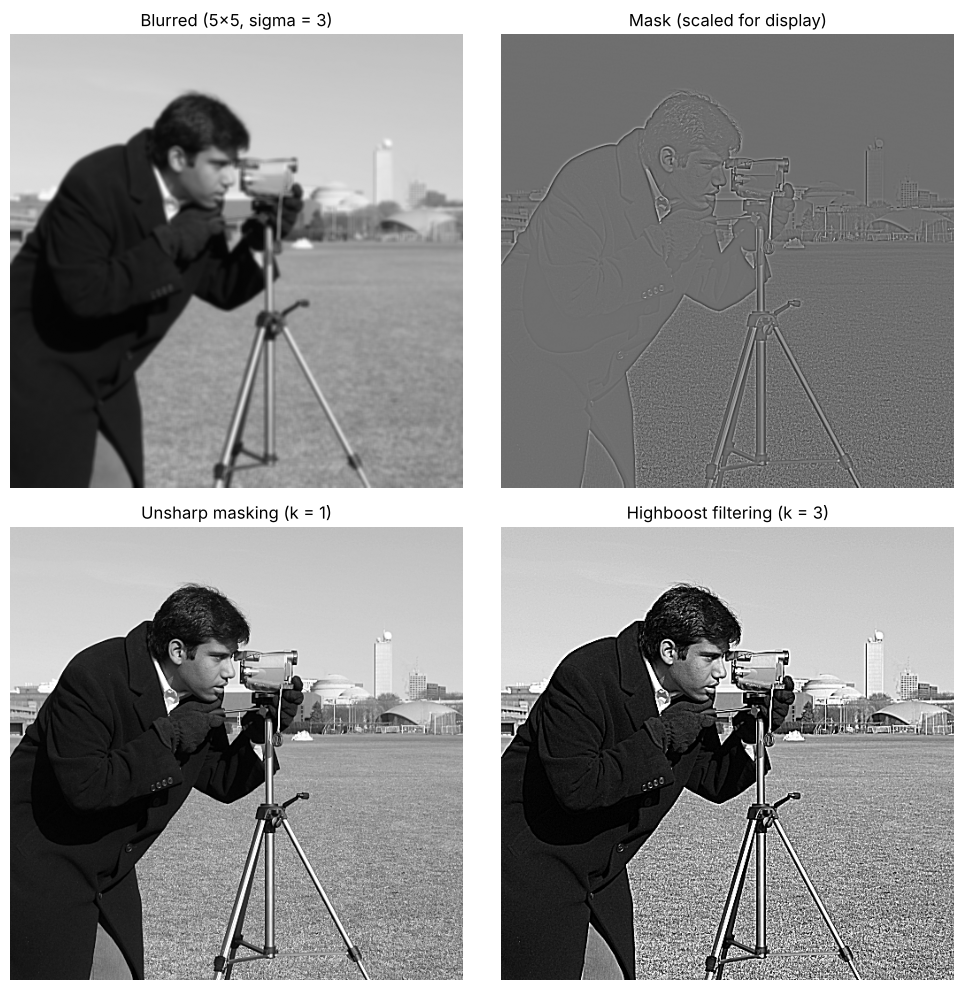

In [6]:
blur_kernel = gaussian_kernel(5, 3)
blurred = convolve(image, blur_kernel)
mask = image - blurred

unsharp_k1 = to_uint8(image + 1.0 * mask)
unsharp_highboost = to_uint8(image + UNSHARP_K * mask)

show([to_uint8(blurred), scale_for_display(mask), unsharp_k1, unsharp_highboost],
     ["Blurred (5x5, sigma = 3)", "Mask (scaled for display)",
      "Unsharp masking (k = 1)", f"Highboost filtering (k = {UNSHARP_K:g})"], cols=2)

## Comparison

The bottom row zooms in on one region, where the differences are easier to see.

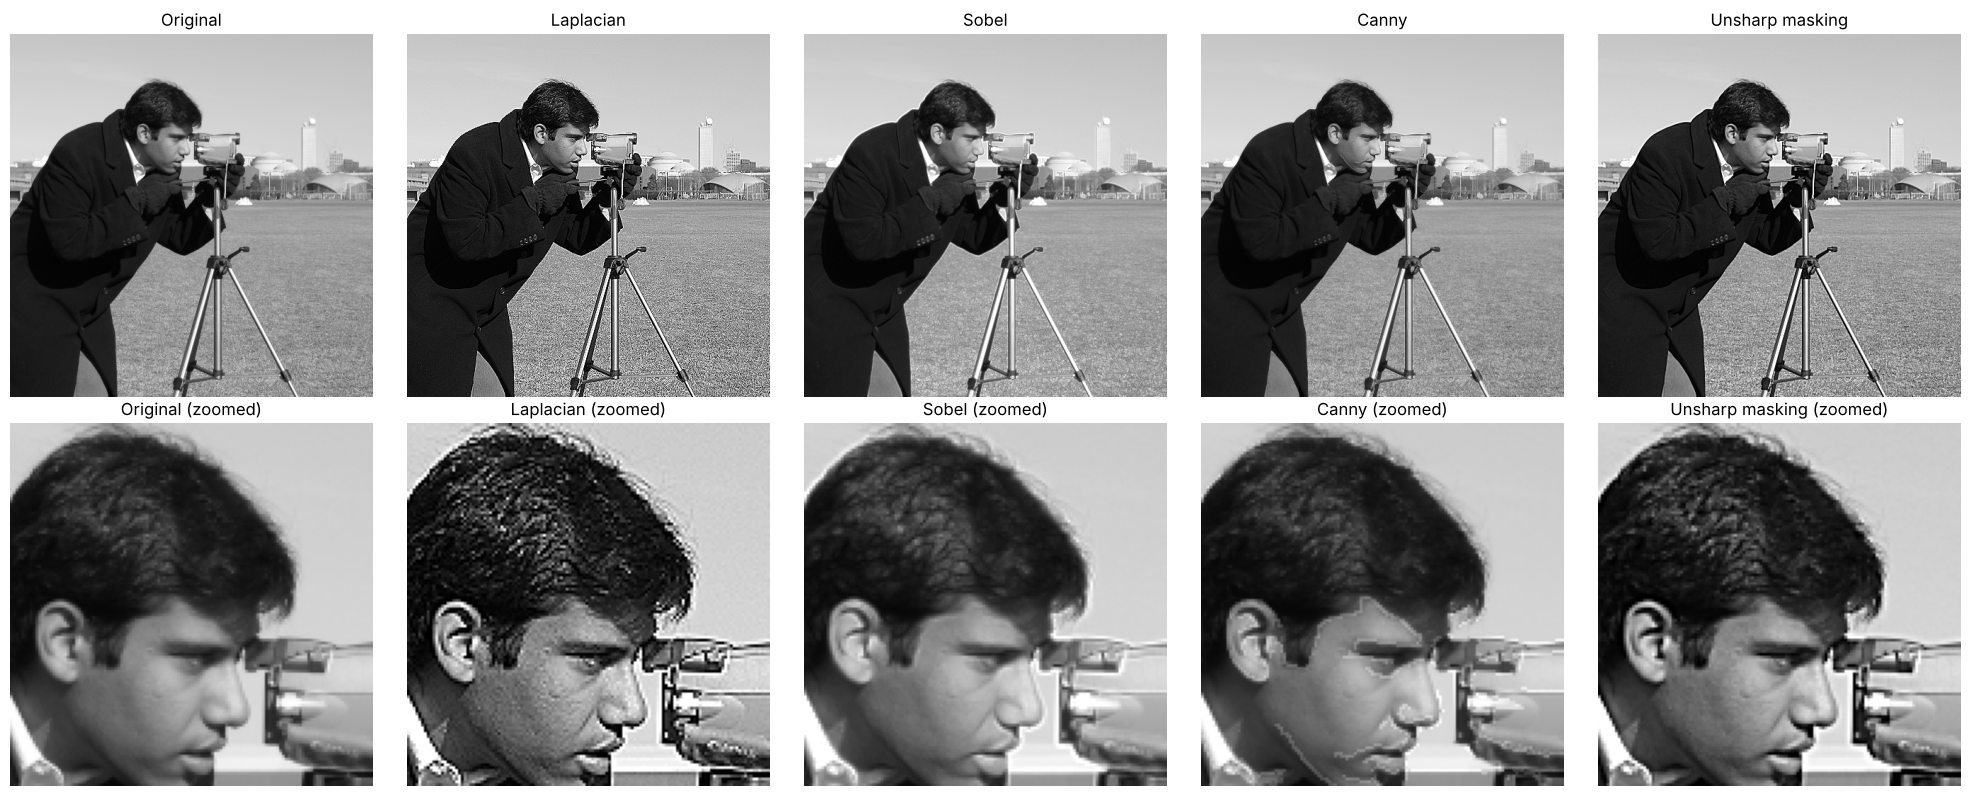

In [7]:
comparison = {
    "Original": image,
    "Laplacian": laplacian_sharpened,
    "Sobel": sobel_sharpened,
    "Canny": canny_sharpened,
    "Unsharp masking": unsharp_k1,
}

# Choose the region to zoom in on
h, w = image.shape
top, left = h // 8, w // 3
crop_h, crop_w = h // 4, w // 4

fig, axes = plt.subplots(2, len(comparison), figsize=(4 * len(comparison), 8))
for i, (title, img) in enumerate(comparison.items()):
    axes[0, i].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(title)
    axes[1, i].imshow(img[top:top + crop_h, left:left + crop_w], cmap="gray", vmin=0, vmax=255)
    axes[1, i].set_title(f"{title} (zoomed)")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## Conclusion

- The **Laplacian** gives strong, crisp sharpening of fine detail, but it also amplifies noise.
- **Sobel** sharpening brightens the areas around edges, because the gradient magnitude is always positive.
- **Canny** gives clean, one-pixel-wide edges. Adding them outlines the main edges but does not enhance fine texture.
- **Unsharp masking** gives the most natural result here, and $k$ controls its strength.